Device: cuda
Row counts  image: {'train': 8108, 'val': 1014, 'test': 1014} | text: {'train': 8108, 'val': 1014, 'test': 1014}
Split sizes: {'train': 8108, 'val': 1014, 'test': 1014}


Re-extracting TEXT features in correct order ...


config.json:   0%|          | 0.00/558 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/843k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  543MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] RobertaModel LOAD REPORT from: vinai/bertweet-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  checkpoint -> missing: [] | unexpected: []
  sanity [val] cosine(old, new) = 1.0000
  sanity [test] cosine(old, new) = 1.0000
Alignment OK: text, image and split labels all match row-for-row.

baseline (your twefuse.py)                              macro-F1 = 0.8215 +- 0.0047
no balance penalty (lambda=0)                           macro-F1 = 0.8187 +- 0.0036
+ cos(T,V) in gate                                      macro-F1 = 0.8205 +- 0.0035
+ GELU                                                  macro-F1 = 0.8181 +- 0.0015
+ dropout (proj 0.1, gate 0.1)                          macro-F1 = 0.8185 +- 0.0040
+ modality dropout (p=0.2)                              macro-F1 = 0.8291 +- 0.0039
+ class-weighted CE                                     macro-F1 = 0.8231 +- 0.0067
+ label smoothing 0.1                                   macro-F1 = 0.8188 +- 0.0036
optimizer: Adam                                         macro-F1 = 0.8212 +- 0.0043
optimizer: SGD+momentum (lr 1e-2)                

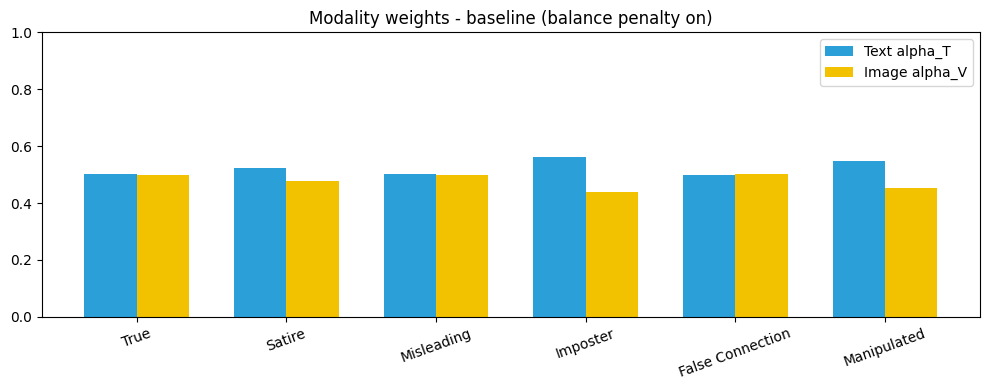


=== Learned alpha_T / alpha_V per class: no balance penalty (use for interpretability claims) ===
True               alpha_T=0.640 +- 0.061   alpha_V=0.360
Satire             alpha_T=0.688 +- 0.058   alpha_V=0.312
Misleading         alpha_T=0.604 +- 0.065   alpha_V=0.396
Imposter           alpha_T=0.763 +- 0.048   alpha_V=0.237
False Connection   alpha_T=0.632 +- 0.053   alpha_V=0.368
Manipulated        alpha_T=0.827 +- 0.034   alpha_V=0.173


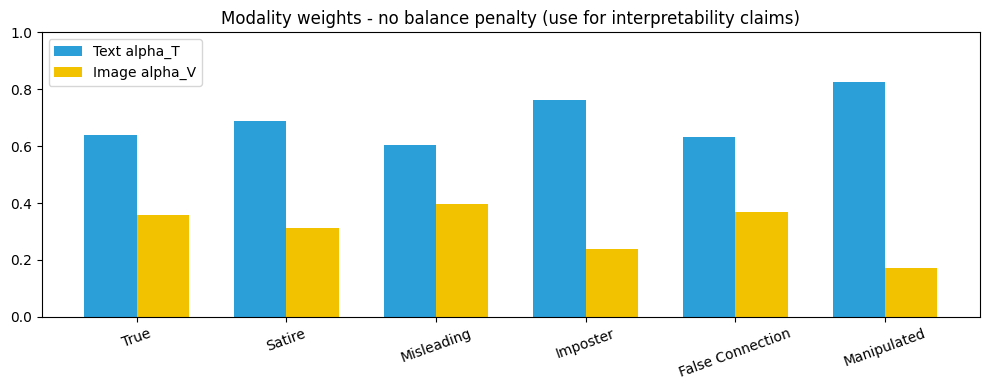

In [1]:
import os, copy, random, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as Fn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from torch.optim.lr_scheduler import LambdaLR

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(os.cpu_count() or 4)
print("Device:", device)

# ---------------- config (edit only if your names differ) ----------------
TEXT_MODEL_NAME = "vinai/bertweet-base"
TEXT_CKPT_NAME = "bertweet_fake_news_model.pt"     # from your text notebook output
CKPT_PREFIX = "bertweet."                          # your classifier stores the encoder as self.bertweet
MAX_LENGTH = 80                                    # must match text-notebook training
TEXT_COLUMN_CANDIDATES = ["text", "clean_title", "title", "headline", "content"]
OUT = "/kaggle/working"

SEEDS = (42, 43, 44)
EPOCHS = 20
BATCH_SIZE = 32
PATIENCE = 4
N_CLASSES = 6
LABEL_NAMES = {0: "True", 1: "Satire", 2: "Misleading", 3: "Imposter",
               4: "False Connection", 5: "Manipulated"}
SPLITS = ("train", "val", "test")


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def find_file(filename, required=True):
    for root, _, files in os.walk("/kaggle/input"):
        if filename in files:
            return os.path.join(root, filename)
    if required:
        raise FileNotFoundError(f"{filename} not found under /kaggle/input")
    return None


# ============================================================
# 1. Rebuild the split exactly as both notebooks did
# ============================================================
def build_split_candidates():
    csv = find_file("master_dataset.csv")
    root = os.path.dirname(csv)
    df = pd.read_csv(csv)
    folders = {s: os.path.join(root, s, s, "images") for s in ("fakenewsnet", "reddit", "twitter")}

    def img_path(row):
        if pd.isna(row["image_path"]):
            return None
        f = folders.get(str(row["source"]).lower())
        if f is None:
            return None
        p = os.path.join(f, os.path.basename(str(row["image_path"])))
        return p if os.path.exists(p) else None

    df["actual_image_path"] = df.apply(img_path, axis=1)
    df = df[df["actual_image_path"].notna()].reset_index(drop=True)
    tcol = next((c for c in TEXT_COLUMN_CANDIDATES if c in df.columns), None)
    if tcol is None:
        raise ValueError(f"No text column found. Columns: {df.columns.tolist()}")

    def split(frame):
        tr, tmp = train_test_split(frame, test_size=0.20, random_state=42, stratify=frame["label"])
        va, te = train_test_split(tmp, test_size=0.50, random_state=42, stratify=tmp["label"])
        return {"train": tr.reset_index(drop=True), "val": va.reset_index(drop=True),
                "test": te.reset_index(drop=True)}

    return [("image-branch split", split(df)),
            ("text-branch split (NaN text dropped)", split(df[df[tcol].notna()]))], tcol


def labels_of(sp, s):
    return torch.tensor(sp[s]["label"].values).long()


def is_aligned(feat_dict, sp):
    return all(len(feat_dict[s]["labels"]) == len(sp[s]) and
               torch.equal(feat_dict[s]["labels"].long(), labels_of(sp, s)) for s in SPLITS)


# ============================================================
# 2. Re-extractors (only used if a side is misaligned)
# ============================================================
@torch.inference_mode()
def extract_text(sp, tcol, old_txt):
    from transformers import AutoTokenizer, AutoModel
    print("Re-extracting TEXT features in correct order ...")
    tok = AutoTokenizer.from_pretrained(TEXT_MODEL_NAME, normalization=True)  # same as training
    enc = AutoModel.from_pretrained(TEXT_MODEL_NAME)
    sd = torch.load(find_file(TEXT_CKPT_NAME), map_location="cpu")
    sd = {k[len(CKPT_PREFIX):]: v for k, v in sd.items() if k.startswith(CKPT_PREFIX)}
    if not sd:
        raise RuntimeError(f"Checkpoint has no '{CKPT_PREFIX}*' keys -- check TEXT_CKPT_NAME / CKPT_PREFIX.")
    res = enc.load_state_dict(sd, strict=False)
    print("  checkpoint -> missing:", res.missing_keys[:4], "| unexpected:", res.unexpected_keys[:4])
    enc = enc.to(device).eval()

    out = {}
    for s in SPLITS:
        texts = sp[s][tcol].fillna("").astype(str).tolist()
        order = np.argsort([len(t) for t in texts])          # length-sorted = less padding = faster
        feats = torch.zeros(len(texts), 768)
        for k in range(0, len(texts), 128):
            idx = order[k:k + 128]
            b = tok([texts[i] for i in idx], padding=True, truncation=True,
                    max_length=MAX_LENGTH, return_tensors="pt").to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16,
                                enabled=device.type == "cuda"):
                h = enc(**b).last_hidden_state[:, 0, :]
            feats[torch.from_numpy(idx)] = h.float().cpu()    # restore original row order
        out[s] = {"features": feats, "labels": labels_of(sp, s)}
        torch.save(out[s], f"{OUT}/{s}_text_features_fixed.pt")

        # sanity: val/test were never shuffled, so old features should match row-by-row
        if s != "train" and old_txt is not None and old_txt[s]["features"].shape == feats.shape:
            cos = Fn.cosine_similarity(old_txt[s]["features"].float(), feats, dim=1).mean().item()
            print(f"  sanity [{s}] cosine(old, new) = {cos:.4f}" +
                  ("" if cos > 0.95 else "   <-- LOW: tokenizer/MAX_LENGTH/checkpoint mismatch?"))
    del enc
    return out


@torch.inference_mode()
def extract_images(sp):
    from transformers import SwinModel
    from torchvision import transforms
    from PIL import Image
    from torch.utils.data import Dataset, DataLoader
    print("Re-extracting IMAGE features in correct order ...")
    tfm = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                              transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    swin = SwinModel.from_pretrained("microsoft/swin-base-patch4-window7-224",
                                     use_safetensors=True).to(device).eval()

    class DS(Dataset):
        def __init__(self, frame): self.p = frame["actual_image_path"].tolist()
        def __len__(self): return len(self.p)
        def __getitem__(self, k): return tfm(Image.open(self.p[k]).convert("RGB"))

    out = {}
    for s in SPLITS:
        dl = DataLoader(DS(sp[s]), batch_size=64, shuffle=False, num_workers=2)
        feats = []
        for x in dl:
            with torch.autocast(device_type=device.type, dtype=torch.float16,
                                enabled=device.type == "cuda"):
                feats.append(swin(pixel_values=x.to(device)).pooler_output.float().cpu())
        out[s] = {"features": torch.cat(feats), "labels": labels_of(sp, s)}
        torch.save(out[s], f"{OUT}/{s}_image_raw_features_fixed.pt")
    del swin
    return out


def load_aligned_features():
    cands, tcol = build_split_candidates()

    def load(kind, fixed_name):
        fixed = [f"{OUT}/{s}_{fixed_name}_fixed.pt" for s in SPLITS]
        if all(os.path.exists(p) for p in fixed):                    # reuse earlier fix
            return {s: torch.load(p) for s, p in zip(SPLITS, fixed)}, True
        return {s: torch.load(find_file(f"{s}_{fixed_name}.pt")) for s in SPLITS}, False

    img, img_cached = load("image", "image_raw_features")
    txt, txt_cached = load("text", "text_features")
    print("Row counts  image:", {s: len(img[s]["labels"]) for s in SPLITS},
          "| text:", {s: len(txt[s]["labels"]) for s in SPLITS})

    # choose the split whose sizes match the image features (the image file defines the split)
    sp = next((c for _, c in cands
               if all(len(c[s]) == len(img[s]["labels"]) for s in SPLITS)), None)
    if sp is None:
        sp = cands[0][1]
        print("WARNING: no candidate split matches image feature sizes -> image features will be rebuilt.")
    print("Split sizes:", {s: len(sp[s]) for s in SPLITS})

    if not is_aligned(img, sp):
        img = extract_images(sp)
    if not is_aligned(txt, sp):
        try:
            old = {s: torch.load(find_file(f"{s}_text_features.pt")) for s in SPLITS}
        except FileNotFoundError:
            old = None
        txt = extract_text(sp, tcol, old)

    assert is_aligned(img, sp) and is_aligned(txt, sp)
    print("Alignment OK: text, image and split labels all match row-for-row.\n")
    return txt, img


# ============================================================
# 3. Model (unchanged from your TweFuse-W)
# ============================================================
class TweFuseW(nn.Module):
    def __init__(self, cfg, text_dim=768, image_dim=1024, shared=768, n_classes=N_CLASSES):
        super().__init__()
        self.cfg = cfg
        act = nn.GELU if cfg["act"] == "gelu" else nn.ReLU

        def proj(d):
            return nn.Sequential(nn.Linear(d, shared), act(), nn.Dropout(cfg["proj_dropout"]),
                                 nn.Linear(shared, shared), nn.LayerNorm(shared))

        self.text_proj, self.img_proj = proj(text_dim), proj(image_dim)
        gate_in = 2 * shared + (1 if cfg["use_cos"] else 0)
        self.gate = nn.Sequential(nn.Linear(gate_in, 128), act(),
                                  nn.Dropout(cfg["gate_dropout"]), nn.Linear(128, 2))
        nn.init.zeros_(self.gate[-1].weight); nn.init.zeros_(self.gate[-1].bias)
        self.classifier = nn.Linear(shared, n_classes)

    def forward(self, text_feats, img_feats):
        T, V = self.text_proj(text_feats), self.img_proj(img_feats)
        p = self.cfg["modality_dropout"]
        if self.training and p > 0:
            r = torch.rand(T.size(0), 1, device=T.device)
            T = T * (r >= p / 2).float()
            V = V * ((r < p / 2) | (r >= p)).float()
        gate_in = torch.cat([T, V], dim=1)
        if self.cfg["use_cos"]:
            gate_in = torch.cat([gate_in, Fn.cosine_similarity(T, V, dim=1).unsqueeze(1)], dim=1)
        a = torch.softmax(self.gate(gate_in), dim=1)
        aT, aV = a[:, 0:1], a[:, 1:2]
        return self.classifier(aT * T + aV * V), aT, aV


def make_optimizer(model, cfg):
    n, lr = cfg["optimizer"], cfg["lr"]
    if n == "adamw": return torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    if n == "adam": return torch.optim.Adam(model.parameters(), lr=lr)
    if n == "sgd_momentum": return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    if n == "rmsprop": return torch.optim.RMSprop(model.parameters(), lr=lr)
    raise ValueError(n)


# ============================================================
# 4. Fast training / evaluation (all data lives on `device`)
# ============================================================
@torch.no_grad()
def evaluate(model, data, ret_weights=False):
    model.eval()
    t, i, y = data
    logits, aT, _ = model(t, i)
    preds, labels = logits.argmax(1).cpu().numpy(), y.cpu().numpy()
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    out = {"acc": accuracy_score(labels, preds), "prec": p, "rec": r, "f1": f1,
           "labels": labels, "preds": preds}
    if ret_weights:
        out["alpha_T"] = aT.squeeze(1).cpu().numpy()
    return out


def run_one(cfg, seed, D, epochs):
    seed_everything(seed)
    Xt, Xi, y = D["train"]
    n = len(y)
    counts = torch.bincount(y, minlength=N_CLASSES).float()
    cw = (counts.sum() / (N_CLASSES * counts.clamp(min=1))) if cfg["class_weighted"] else None
    crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=cfg["label_smoothing"])

    model = TweFuseW(cfg).to(device)
    opt = make_optimizer(model, cfg)
    total = math.ceil(n / BATCH_SIZE) * epochs
    warm = int(total * 0.1)
    sched = LambdaLR(opt, lambda s: s / max(1, warm) if s < warm
                     else max(0.0, (total - s) / max(1, total - warm)))
    g = torch.Generator().manual_seed(seed)

    best_f1, best_state, bad = -1.0, None, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=g).to(device)
        for k in range(0, n, BATCH_SIZE):
            idx = perm[k:k + BATCH_SIZE]
            logits, aT, _ = model(Xt[idx], Xi[idx])
            loss = crit(logits, y[idx])
            if cfg["balance_lambda"] > 0:
                loss = loss + cfg["balance_lambda"] * ((aT - 0.5) ** 2).mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
        f1 = evaluate(model, D["val"])["f1"]
        if f1 > best_f1:
            best_f1, bad = f1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    res = evaluate(model, D["test"], ret_weights=True)
    res["val_f1"] = best_f1
    return res


# ============================================================
# 5. Experiment grid
# ============================================================
BASE = dict(name="baseline (your twefuse.py)", act="relu", use_cos=False,
            proj_dropout=0.0, gate_dropout=0.0, modality_dropout=0.0,
            class_weighted=False, label_smoothing=0.0, balance_lambda=0.5,
            optimizer="adamw", lr=3e-5)


def variant(name, **kw):
    cfg = dict(BASE); cfg.update(kw); cfg["name"] = name
    return cfg


EXPERIMENTS = [
    BASE,
    variant("no balance penalty (lambda=0)", balance_lambda=0.0),
    variant("+ cos(T,V) in gate", use_cos=True),
    variant("+ GELU", act="gelu"),
    variant("+ dropout (proj 0.1, gate 0.1)", proj_dropout=0.1, gate_dropout=0.1),
    variant("+ modality dropout (p=0.2)", modality_dropout=0.2),
    variant("+ class-weighted CE", class_weighted=True),
    variant("+ label smoothing 0.1", label_smoothing=0.1),
    variant("optimizer: Adam", optimizer="adam"),
    variant("optimizer: SGD+momentum (lr 1e-2)", optimizer="sgd_momentum", lr=1e-2),
    variant("optimizer: RMSProp (lr 1e-4)", optimizer="rmsprop", lr=1e-4),
    variant("combo: cos + dropout + modality drop + weighted",
            use_cos=True, proj_dropout=0.1, gate_dropout=0.1,
            modality_dropout=0.2, class_weighted=True),
]


def report_weights(result, title):
    print(f"\n=== Learned alpha_T / alpha_V per class: {title} ===")
    mT = []
    for c in range(N_CLASSES):
        m = result["labels"] == c
        if m.sum() == 0:
            mT.append(np.nan); continue
        a = result["alpha_T"][m]
        mT.append(a.mean())
        print(f"{LABEL_NAMES[c]:18s} alpha_T={a.mean():.3f} +- {a.std():.3f}   alpha_V={1 - a.mean():.3f}")
    x, w = np.arange(N_CLASSES), 0.35
    plt.figure(figsize=(10, 4))
    plt.bar(x - w / 2, mT, w, label="Text alpha_T", color="#2b9fd8")
    plt.bar(x + w / 2, [1 - v for v in mT], w, label="Image alpha_V", color="#f2c200")
    plt.xticks(x, [LABEL_NAMES[i] for i in range(N_CLASSES)], rotation=20)
    plt.ylim(0, 1); plt.title(f"Modality weights - {title}"); plt.legend(); plt.tight_layout(); plt.show()


# ============================================================
# 6. One call does everything
# ============================================================
def main(quick=False, seeds=SEEDS, epochs=EPOCHS):
    """quick=True -> 1 seed, 12 epochs (a few minutes even on CPU)."""
    if quick:
        seeds, epochs = (seeds[0],), 12
    txt, img = load_aligned_features()
    D = {s: (txt[s]["features"].float().to(device), img[s]["features"].float().to(device),
             img[s]["labels"].long().to(device)) for s in SPLITS}

    rows, all_results = [], {}
    for cfg in EXPERIMENTS:
        res = [run_one(cfg, s, D, epochs) for s in seeds]
        all_results[cfg["name"]] = res
        f1s = np.array([r["f1"] for r in res])
        rows.append({"Configuration": cfg["name"],
                     "Macro-F1": f"{f1s.mean():.4f} +- {f1s.std():.4f}",
                     "Acc": f"{np.mean([r['acc'] for r in res]):.4f}",
                     "Macro-P": f"{np.mean([r['prec'] for r in res]):.4f}",
                     "Macro-R": f"{np.mean([r['rec'] for r in res]):.4f}",
                     "_f1": f1s.mean()})
        print(f"{cfg['name']:55s} macro-F1 = {f1s.mean():.4f} +- {f1s.std():.4f}")

    table = pd.DataFrame(rows)
    table["dF1 vs baseline"] = (table["_f1"] - table.loc[0, "_f1"]).map(lambda d: f"{d:+.4f}")
    table = table.drop(columns="_f1")
    print("\n" + "=" * 100)
    print(f"ABLATION TABLE (test split, mean +- std over seeds {list(seeds)})")
    print("=" * 100)
    print(table.to_string(index=False))
    table.to_csv(f"{OUT}/twefuse_ablation.csv", index=False)

    report_weights(all_results[BASE["name"]][0], "baseline (balance penalty on)")
    report_weights(all_results["no balance penalty (lambda=0)"][0],
                   "no balance penalty (use for interpretability claims)")
    return table, all_results


if __name__ == "__main__":
    table, all_results = main(quick=False)   # set quick=True for a fast smoke run first